In [1]:
import pandas as pd
import requests
import logging
import holidays

logging.basicConfig(level=logging.INFO)

class Eco2mixFeaturesMinute:
    """Adds selected external features to 30-min Eco2mix data."""

    def __init__(self, df):
        self.df = df.copy()
        self.df["Datetime"] = pd.to_datetime(self.df["Datetime"])

    def add_temperature(self, latitude=48.85, longitude=2.35):
        self.df["Hour"] = self.df["Datetime"].dt.floor("h")
        start_date = self.df["Hour"].min().strftime("%Y-%m-%d")
        end_date = self.df["Hour"].max().strftime("%Y-%m-%d")

        url = "https://archive-api.open-meteo.com/v1/archive"
        params = {
            "latitude": latitude,
            "longitude": longitude,
            "start_date": start_date,
            "end_date": end_date,
            "hourly": "temperature",
            "timezone": "Europe/Paris"
        }

        try:
            response = requests.get(url, params=params)
            response.raise_for_status()
            data = response.json()
            temp_df = pd.DataFrame(data["hourly"])
            temp_df["Hour"] = pd.to_datetime(temp_df["time"])
            temp_df.drop(columns=["time"], inplace=True)
            self.df = self.df.merge(temp_df, on="Hour", how="left")
            self.df.drop(columns=["Hour"], inplace=True)

            logging.info("Temperature features added.")
        except requests.RequestException as e:
            logging.error(f"[API Error - Temperature] {e}")

    def add_sunshine(self, latitude=48.85, longitude=2.35):
        self.df["Date"] = self.df["Datetime"].dt.date
        start_date = min(self.df["Date"]).strftime("%Y-%m-%d")
        end_date = max(self.df["Date"]).strftime("%Y-%m-%d")

        url = "https://archive-api.open-meteo.com/v1/archive"
        params = {
            "latitude": latitude,
            "longitude": longitude,
            "start_date": start_date,
            "end_date": end_date,
            "daily": "sunshine_duration",
            "timezone": "Europe/Paris"
        }

        try:
            response = requests.get(url, params=params)
            response.raise_for_status()
            data = response.json()
            sun_df = pd.DataFrame(data["daily"])
            sun_df["Date"] = pd.to_datetime(sun_df["time"]).dt.date
            sun_df.drop(columns=["time"], inplace=True)
            self.df = self.df.merge(sun_df, on="Date", how="left")
            self.df.drop(columns=["Date"], inplace=True)
            logging.info("Sunshine features added.")
        except requests.RequestException as e:
            logging.error(f"[API Error - Sunshine] {e}")

    def add_weekday(self):
        self.df["Date"] = self.df["Datetime"].dt.date
        jours_fr = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
        self.df["weekday"] = pd.to_datetime(self.df["Date"]).dt.dayofweek.apply(lambda x: jours_fr[x])
        self.df.drop(columns=["Date"], inplace=True)
        logging.info("Weekday column added.")

    def add_month(self):
        self.df["Date"] = self.df["Datetime"].dt.date
        mois_fr = [
            "janvier", "février", "mars", "avril", "mai", "juin",
            "juillet", "août", "septembre", "octobre", "novembre", "décembre"
        ]
        self.df["month"] = pd.to_datetime(self.df["Date"]).dt.month.apply(lambda x: mois_fr[x - 1])
        self.df.drop(columns=["Date"], inplace=True)
        logging.info("Month column added.")

    def add_season(self):
        self.df["Date"] = self.df["Datetime"].dt.date

        def get_season(month):
            return (
                "hiver" if month in [12, 1, 2] else
                "printemps" if month in [3, 4, 5] else
                "été" if month in [6, 7, 8] else
                "automne"
            )
        self.df["season"] = pd.to_datetime(self.df["Date"]).dt.month.apply(get_season)
        self.df.drop(columns=["Date"], inplace=True)
        logging.info("Season column added.")

    def add_vacation(self):
        self.df["Date"] = self.df["Datetime"].dt.date
        years = pd.to_datetime(self.df["Date"]).dt.year.unique()
        public_holidays = holidays.FR(years=years)

        zone_vacations_by_year = {
            "winter": ("02-05", "03-07"),
            "spring": ("04-09", "05-09"),
            "summer": ("07-06", "08-31"),
            "Toussaint": ("10-17", "11-02"),
            "christmas": ("12-18", "12-31")
        }

        vacations = set()
        for year in years:
            for start, end in zone_vacations_by_year.values():
                vacations.update(pd.date_range(start=f"{year}-{start}", end=f"{year}-{end}").date)

        self.df["is_vacation"] = self.df["Date"].apply(lambda d: int(d in public_holidays or d in vacations))
        self.df.drop(columns=["Date"], inplace=True)
        logging.info("Vacation flag added.")

    def run(self, include=None):
        include = include or []
        if "temperature" in include:
            self.add_temperature()
        if "sunshine" in include:
            self.add_sunshine()
        if "weekday" in include:
            self.add_weekday()
        if "month" in include:
            self.add_month()
        if "season" in include:
            self.add_season()
        if "vacation" in include:
            self.add_vacation()
        return self.df

In [2]:
import os
import zipfile
import requests
import pandas as pd
from datetime import datetime, timedelta
from pathlib import Path
import logging

logger = logging.getLogger(__name__)

def read_df(path):
    """Read .xls eco2mix file as tab-separated with latin1 encoding."""
    return pd.read_csv(path, sep="\t", encoding="latin1", index_col=False, low_memory=False)

class Eco2mixLivePreparer:
    """
    Prépare les données Eco2mix récentes ou chargées depuis un fichier local
    pour l'inférence TFT, avec enrichissement des features externes.
    """
    ECO2MIX_LIVE_URL = "https://eco2mix.rte-france.com/download/eco2mix/eCO2mix_RTE_En-cours-TR.zip"

    def __init__(self, tmp_dir="eco2mix_inference"):
        self.tmp_dir = Path(tmp_dir)
        self.tmp_dir.mkdir(parents=True, exist_ok=True)

    def load_and_prepare(self, target_date: str, xls_path: str = None) -> pd.DataFrame:
        target_dt = pd.to_datetime(target_date)
        start_dt = target_dt - timedelta(days=7)
        end_dt = target_dt + timedelta(hours=23, minutes=30)

        logger.info(f"Preparing data for inference on target date: {target_date}")

        # Étape 1 : lire depuis fichier local si xls_path est fourni
        if xls_path:
            xls_path = Path(xls_path)
            if not xls_path.exists():
                raise FileNotFoundError(f"Provided XLS path not found: {xls_path}")
            logger.info(f"Using local XLS file: {xls_path}")
        else:
            # Sinon, téléchargement depuis le site officiel
            zip_path = self.tmp_dir / "live.zip"
            response = requests.get(self.ECO2MIX_LIVE_URL)
            with open(zip_path, "wb") as f:
                f.write(response.content)
            logger.info(f"Downloaded Eco2mix live ZIP to {zip_path}")

            with zipfile.ZipFile(zip_path, "r") as zip_ref:
                zip_ref.extractall(self.tmp_dir)
            logger.info(f"Extracted ZIP content to {self.tmp_dir}")

            xls_files = list(self.tmp_dir.glob("*.xls"))
            if not xls_files:
                raise FileNotFoundError("No .xls file found in the archive.")
            xls_path = xls_files[0]
            logger.info(f"Found XLS file: {xls_path.name}")

        # Étape 2 : lecture et filtrage
        df = read_df(xls_path)
        df = df.iloc[:-1]  # remove summary row
        df = df[["Date", "Heures", "Consommation"]].dropna()
        df["Datetime"] = pd.to_datetime(df["Date"].astype(str) + " " + df["Heures"], errors="coerce")
        df = df[["Datetime", "Consommation"]].dropna()
        df = df[df["Datetime"].dt.minute.isin([0, 30])]
        df = df[df["Datetime"].between(start_dt, end_dt)]
        df = df.sort_values("Datetime").reset_index(drop=True)

        expected_rows = (7 + 1) * 48
        if len(df) < expected_rows:
            logger.warning(f"Only {len(df)} rows found, expected {expected_rows}. Data may be incomplete.")
        else:
            logger.info(f"Loaded {len(df)} rows of 30-minute consumption data.")

        # Étape 3 : enrichissement des features
        df_features = Eco2mixFeaturesMinute(df)
        df = df_features.run(include=["temperature", "sunshine", "weekday", "month", "season", "vacation"])
        logger.info("Added external features to data.")
        return df

In [3]:
from pytorch_forecasting import TimeSeriesDataSet
import pandas as pd

def rebuild_reference_dataset(df: pd.DataFrame, params: dict) -> TimeSeriesDataSet:
    """
    Rebuild the reference TimeSeriesDataSet using the same structure as during training.

    Parameters:
    - df: full input DataFrame with 'Datetime', 'Consommation', and all features
    - params: dict of training parameters (same as used in training phase)

    Returns:
    - TimeSeriesDataSet object for inference use
    """
    df = df.copy()
    df["Datetime"] = pd.to_datetime(df["Datetime"])
    df = df.sort_values("Datetime").reset_index(drop=True)
    df["time_idx"] = range(len(df))
    df["series_id"] = "France"

    dataset = TimeSeriesDataSet(
        df,
        time_idx="time_idx",
        target="Consommation",
        group_ids=["series_id"],
        max_encoder_length=params.get("max_encoder_length", 288),
        max_prediction_length=params.get("max_prediction_length", 48),
        time_varying_known_reals=params.get("known_reals", []),
        time_varying_unknown_reals=params.get("unknown_reals", []),
        time_varying_known_categoricals=params.get("known_categoricals", []),
        time_varying_unknown_categoricals=params.get("unknown_categoricals", []),
        static_reals=params.get("static_reals", []),
        static_categoricals=params.get("static_categoricals", []),
        target_normalizer=params.get("target_normalizer", None),
        add_relative_time_idx=params.get("add_relative_time_idx", True),
        add_target_scales=params.get("add_target_scales", True),
        add_encoder_length=params.get("add_encoder_length", True)
    )

    return dataset

In [4]:
import matplotlib.pyplot as plt
from pytorch_forecasting import TemporalFusionTransformer
from pytorch_forecasting.data import TimeSeriesDataSet
import pandas as pd

class TFTInference:
    def __init__(self, model_ckpt_path, reference_dataset):
        self.model = TemporalFusionTransformer.load_from_checkpoint(model_ckpt_path)
        self.reference_dataset = reference_dataset

    def predict(self, df_input: pd.DataFrame) -> dict:
        df_input = df_input.copy()
        df_input["Datetime"] = pd.to_datetime(df_input["Datetime"])
        df_input = df_input.sort_values("Datetime").reset_index(drop=True)
        df_input["time_idx"] = range(len(df_input))
        df_input["series_id"] = "France"

        # Extract true consumption of the prediction day
        last_day = df_input["Datetime"].dt.date.max()
        mask = df_input["Datetime"].dt.date == last_day
        true_values = df_input.loc[mask, "Consommation"].values.tolist()

        # Prepare dataset
        pred_dataset = TimeSeriesDataSet.from_dataset(
            self.reference_dataset,
            df_input,
            predict=True,
            stop_randomization=True
        )

        loader = pred_dataset.to_dataloader(train=False, batch_size=1)
        raw_predictions = self.model.predict(loader, mode="raw", return_x=True)
        all_quantiles = raw_predictions.output.prediction[0].detach().cpu().numpy()  # [48, 3]

        # Plot with ground truth
        quantile_labels = ["q2_5", "q50", "q97_5"]
        fig, ax = plt.subplots(figsize=(12, 6))
        for i, label in enumerate(quantile_labels):
            ax.plot(all_quantiles[:, i], label=label)
        if len(true_values) == 48:
            ax.plot(true_values, label="True consumption", color="black", linewidth=2)
        ax.set_title("TFT Forecast – Quantile predictions vs ground truth")
        ax.set_xlabel("30-minute steps")
        ax.set_ylabel("Consumption (MW)")
        ax.legend()
        ax.grid(True)
        fig.tight_layout()

        return {
            "prediction": all_quantiles.tolist(),
            "quantiles": quantile_labels,
            "ground_truth": true_values,
            "figure": fig
        }

INFO:__main__:Preparing data for inference on target date: 2021-05-08
INFO:__main__:Using local XLS file: eCO2mix_RTE_Annuel-Definitif_2021.xls
INFO:__main__:Loaded 384 rows of 30-minute consumption data.
INFO:root:Temperature features added.
INFO:root:Sunshine features added.
INFO:root:Weekday column added.
INFO:root:Month column added.
INFO:root:Season column added.
INFO:root:Vacation flag added.
INFO:__main__:Added external features to data.
/home/hassani/EPSI/MSPR/tft-env/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:209: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/home/hassani/EPSI/MSPR/tft-env/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:209: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters

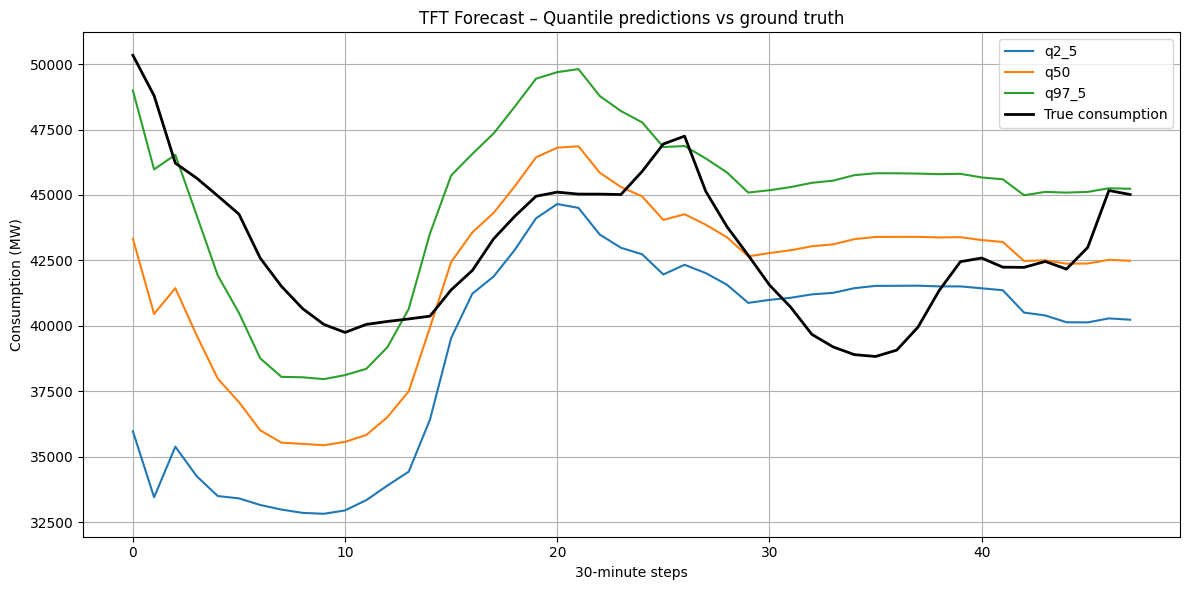

In [9]:
import pickle
# Prepare input data
preparer = Eco2mixLivePreparer()
df_input = preparer.load_and_prepare("2021-05-08", xls_path = "eCO2mix_RTE_Annuel-Definitif_2021.xls")

params = {
    "max_encoder_length": 6*48,
    "max_prediction_length": 48,
    "known_reals": ["time_idx", "temperature", "is_vacation"],
    "unknown_reals": ["Consommation", "sunshine_duration"],
    "known_categoricals": ["weekday", "month", "season"],
}

# recreate the reference dataset
reference_dataset = rebuild_reference_dataset(df_input, params)

# Inference
model_path="../data/06_models/tft/epoch=10-val_loss=790.21.ckpt"
engine = TFTInference(model_path, reference_dataset)
result = engine.predict(df_input)